In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Generating figures...


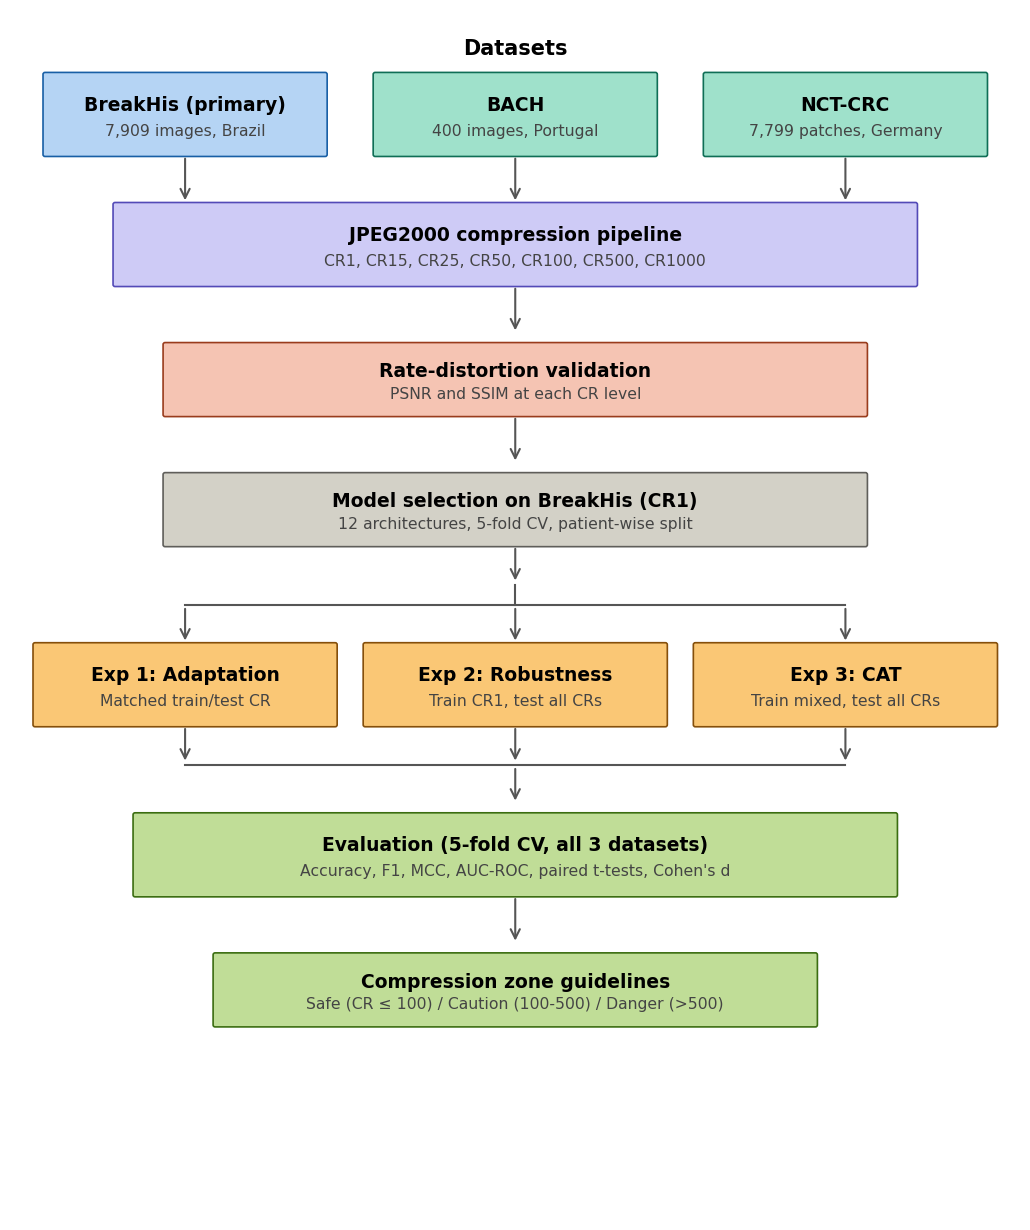

  ✅ fig_workflow


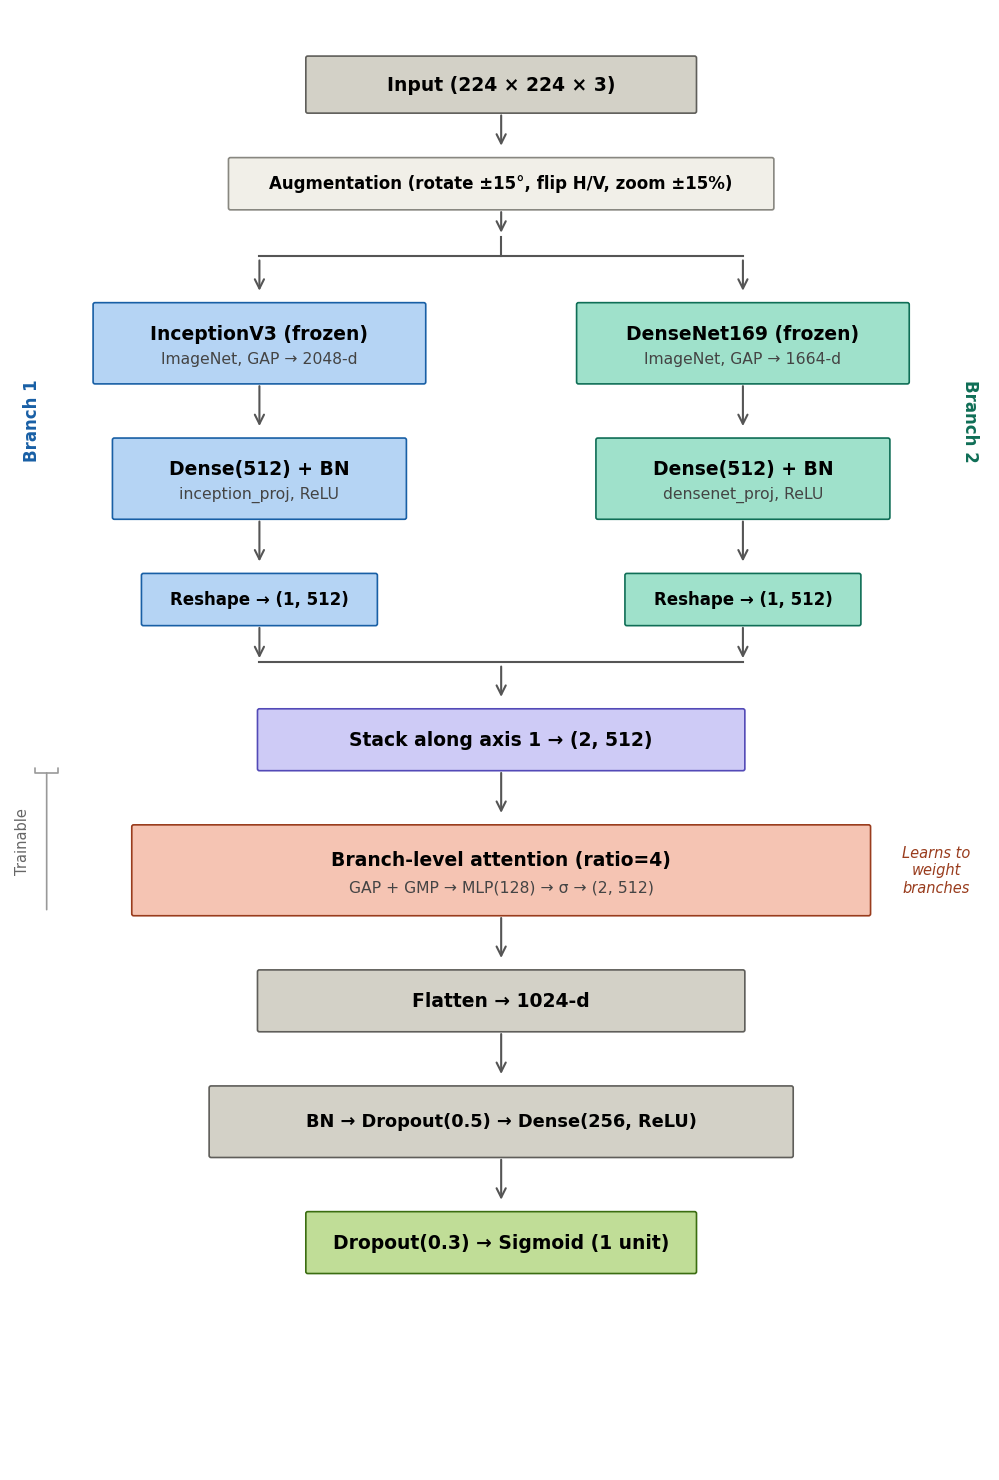

  ✅ fig_architecture


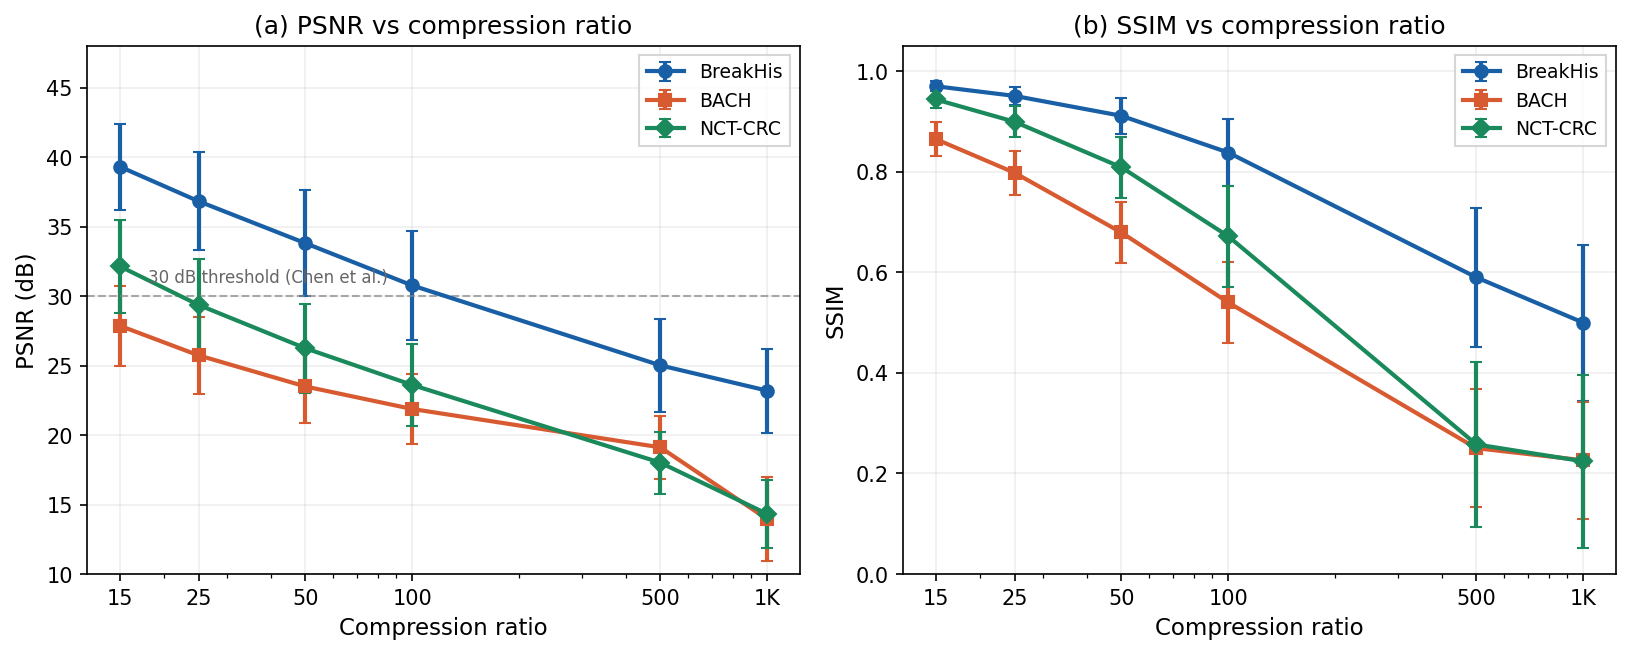

  ✅ fig_rate_distortion


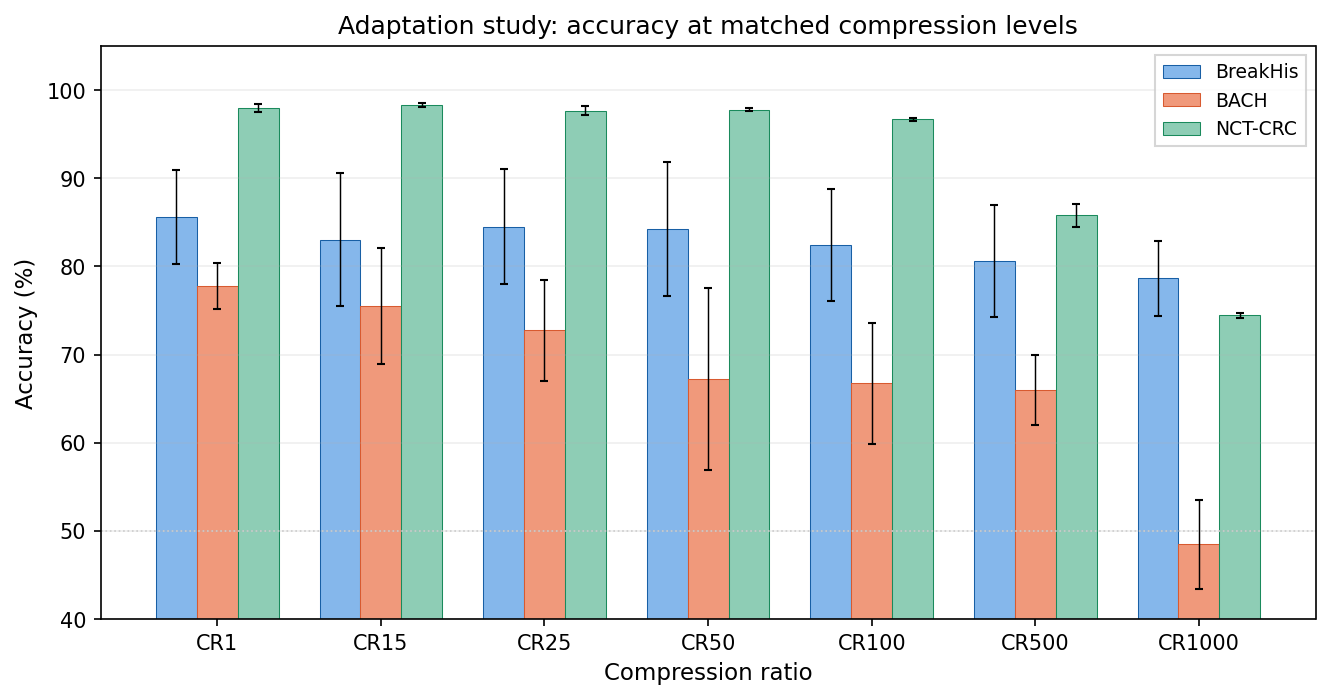

  ✅ fig_adaptation


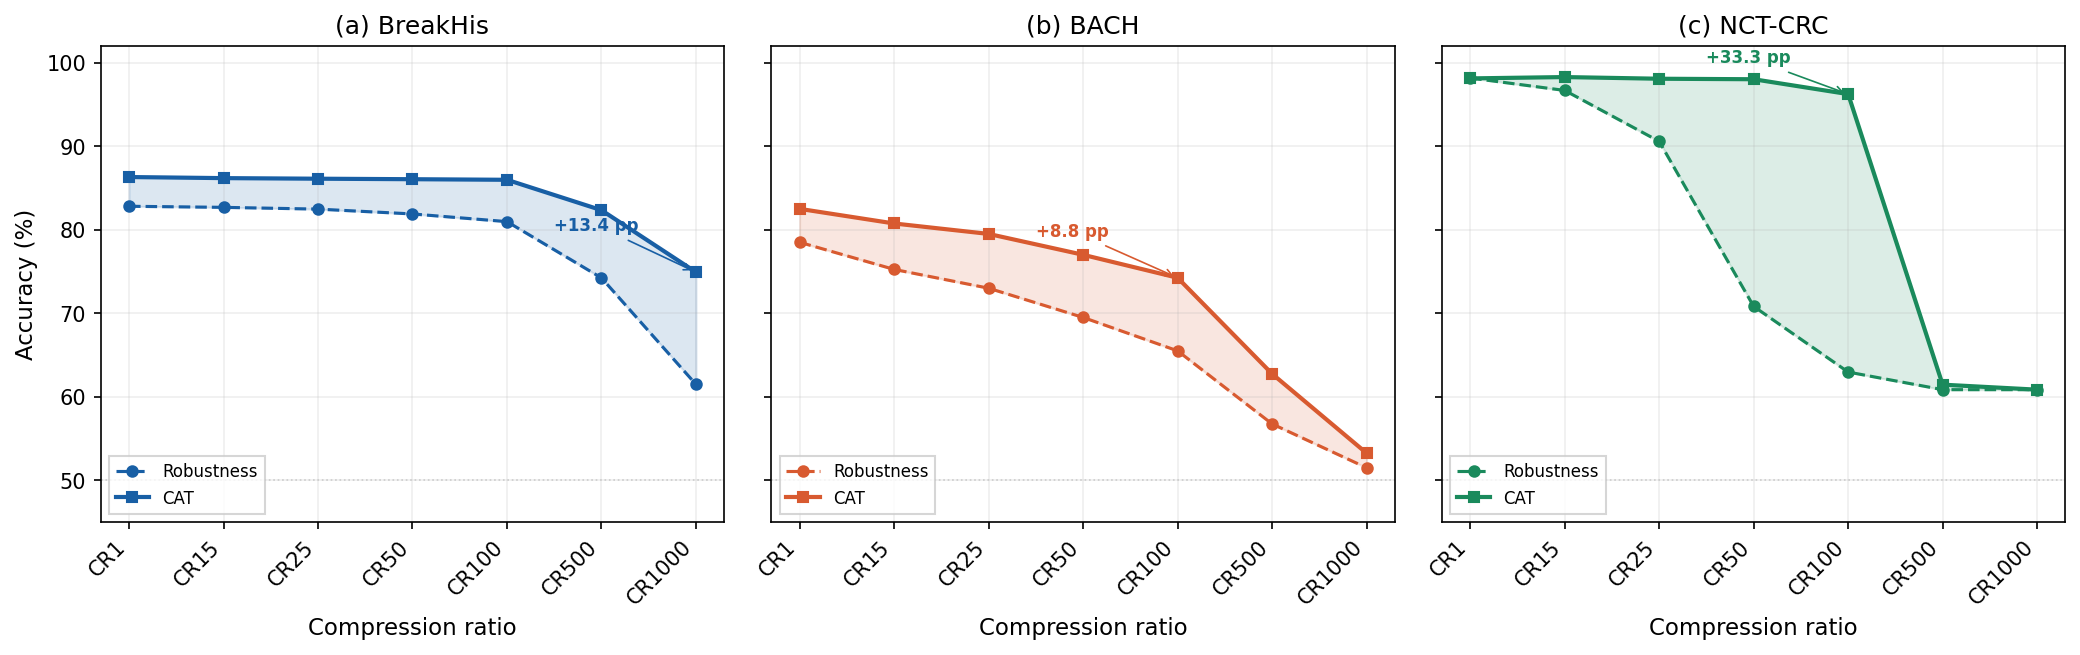

  ✅ fig_robustness_vs_cat


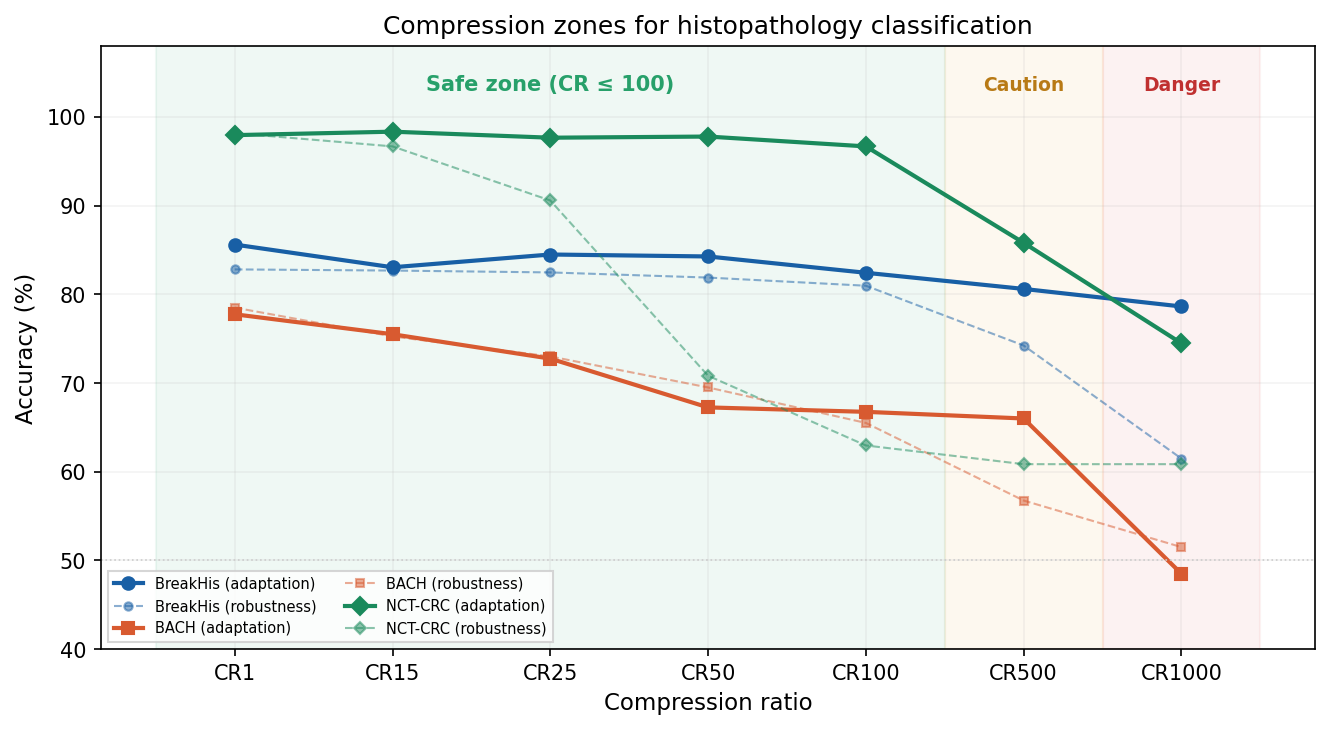

  ✅ fig_compression_zones


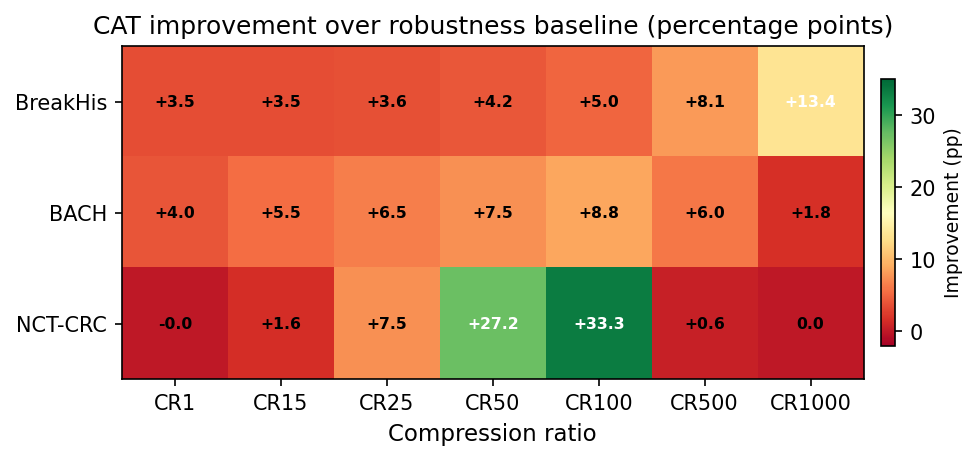

  ✅ fig_cat_improvement


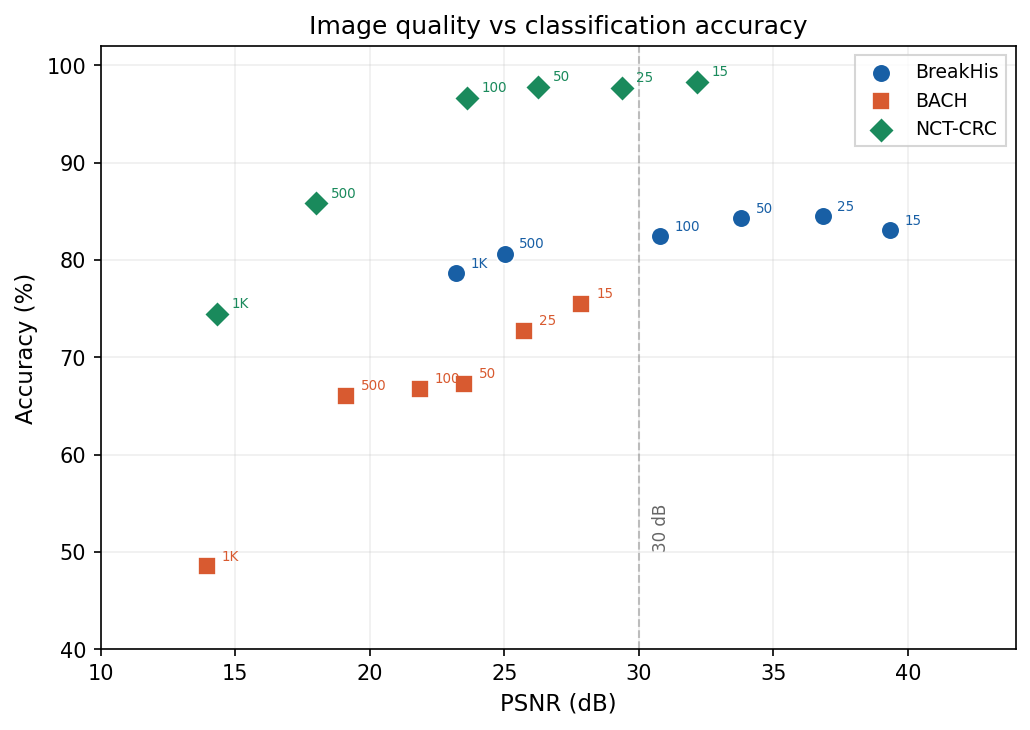

  ✅ fig_psnr_vs_accuracy

  All 8 figures saved to: /content/drive/MyDrive/JPEG2000_Paper_Final/figures

  fig_workflow.pdf           — §3   Experimental pipeline
  fig_architecture.pdf       — §3.3 Model architecture (CORRECTED)
  fig_rate_distortion.pdf    — §4.1 PSNR + SSIM curves
  fig_adaptation.pdf         — §4.2 Adaptation bar chart
  fig_robustness_vs_cat.pdf  — §4.4 Robustness vs CAT (3 panels)
  fig_compression_zones.pdf  — §5.1 Compression zones
  fig_cat_improvement.pdf    — §5.3 CAT improvement heatmap
  fig_psnr_vs_accuracy.pdf   — §5.2 PSNR vs accuracy scatter



In [2]:
"""
ALL FIGURES FOR JPEG2000 PAPER
==============================
Run in Colab (CPU is fine, no GPU needed).
Generates 8 figures total:
  1. fig_workflow.pdf         — §3 experimental workflow
  2. fig_architecture.pdf     — §3.3.2 model architecture (CORRECTED)
  3. fig_rate_distortion.pdf  — §4.1 PSNR + SSIM curves
  4. fig_adaptation.pdf       — §4.2 adaptation bar chart
  5. fig_robustness_vs_cat.pdf — §4.4 robustness vs CAT (3 panels)
  6. fig_compression_zones.pdf — §5.1 zone visualization
  7. fig_cat_improvement.pdf  — §5.3 CAT heatmap
  8. fig_psnr_vs_accuracy.pdf — §5.2 scatter plot
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import os

OUTPUT_DIR = '/content/drive/MyDrive/JPEG2000_Paper_Final/figures'
os.makedirs(OUTPUT_DIR, exist_ok=True)

plt.rcParams.update({
    'font.size': 11,
    'font.family': 'sans-serif',
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
})

# ════════════════════════════════════════════
# DATA (NCT-CRC = BALANCED SPLIT, AUTHORITATIVE)
# ════════════════════════════════════════════

CR_LABELS = ['CR1','CR15','CR25','CR50','CR100','CR500','CR1000']
cr_x = [15, 25, 50, 100, 500, 1000]

C_BH = '#185FA5'; C_BA = '#D85A30'; C_NC = '#1A8A5C'
colors = {'BreakHis': C_BH, 'BACH': C_BA, 'NCT-CRC': C_NC}
markers = {'BreakHis': 'o', 'BACH': 's', 'NCT-CRC': 'D'}

rd = {
    'BreakHis': {'psnr': [39.32,36.83,33.81,30.77,25.02,23.20],
                 'psnr_sd': [3.10,3.53,3.81,3.89,3.33,3.03],
                 'ssim': [0.97,0.9508,0.9112,0.8382,0.59,0.50],
                 'ssim_sd': [0.0097,0.0181,0.0356,0.0657,0.1384,0.1552]},
    'BACH':     {'psnr': [27.87,25.74,23.50,21.88,19.12,13.96],
                 'psnr_sd': [2.87,2.78,2.66,2.55,2.25,2.99],
                 'ssim': [0.8649,0.798,0.6792,0.5401,0.2503,0.2263],
                 'ssim_sd': [0.0341,0.0437,0.0605,0.0809,0.1171,0.1161]},
    'NCT-CRC': {'psnr': [32.15,29.37,26.25,23.61,18.02,14.33],
                 'psnr_sd': [3.34,3.33,3.21,2.96,2.23,2.42],
                 'ssim': [0.9437,0.8994,0.8088,0.6718,0.2579,0.2242],
                 'ssim_sd': [0.016,0.0305,0.0602,0.1001,0.1647,0.1723]},
}

adapt = {
    'BreakHis': [85.61,83.05,84.49,84.27,82.43,80.61,78.63],
    'BreakHis_sd': [5.34,7.57,6.52,7.59,6.38,6.38,4.29],
    'BACH': [77.75,75.50,72.75,67.25,66.75,66.00,48.50],
    'BACH_sd': [2.62,6.56,5.71,10.35,6.87,3.98,5.04],
    'NCT-CRC': [97.95,98.34,97.66,97.79,96.68,85.81,74.48],
    'NCT-CRC_sd': [0.45,0.21,0.50,0.18,0.20,1.32,0.28],
}

robust = {
    'BreakHis': [82.81,82.68,82.47,81.89,80.97,74.23,61.48],
    'BACH': [78.50,75.25,73.00,69.50,65.50,56.75,51.50],
    'NCT-CRC': [98.17,96.68,90.58,70.82,62.96,60.85,60.85],
}

cat = {
    'BreakHis': [86.31,86.18,86.11,86.05,85.98,82.34,74.92],
    'BACH': [82.50,80.75,79.50,77.00,74.25,62.75,53.25],
    'NCT-CRC': [98.12,98.28,98.08,98.02,96.24,61.45,60.85],
}


# ════════════════════════════════════════════
# HELPER FUNCTION
# ════════════════════════════════════════════

def draw_box(ax, x, y, w, h, text, subtext=None, color='#E6F1FB',
             edgecolor='#185FA5', fontsize=9, bold=True):
    box = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02",
                          facecolor=color, edgecolor=edgecolor,
                          linewidth=0.8, zorder=2)
    ax.add_patch(box)
    weight = 'bold' if bold else 'normal'
    if subtext:
        ax.text(x + w/2, y + h*0.62, text, ha='center', va='center',
                fontsize=fontsize, fontweight=weight, zorder=3)
        ax.text(x + w/2, y + h*0.3, subtext, ha='center', va='center',
                fontsize=fontsize-1.5, color='#444', zorder=3)
    else:
        ax.text(x + w/2, y + h/2, text, ha='center', va='center',
                fontsize=fontsize, fontweight=weight, zorder=3)

def draw_arrow(ax, x1, y1, x2, y2):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color='#555',
                                lw=1.0, connectionstyle='arc3,rad=0'))

def save(name):
    plt.savefig(os.path.join(OUTPUT_DIR, f'{name}.pdf'))
    plt.savefig(os.path.join(OUTPUT_DIR, f'{name}.png'))
    plt.show()
    print(f"  ✅ {name}")


# ════════════════════════════════════════════
# FIG 1: EXPERIMENTAL WORKFLOW
# ════════════════════════════════════════════
print("Generating figures...")

fig, ax = plt.subplots(1, 1, figsize=(7, 8.5))
ax.set_xlim(0, 10); ax.set_ylim(0, 12); ax.axis('off'); ax.set_aspect('equal')

ax.text(5, 11.6, 'Datasets', ha='center', fontsize=10, fontweight='bold')
draw_box(ax, 0.3, 10.6, 2.8, 0.8, 'BreakHis (primary)', '7,909 images, Brazil',
         color='#B5D4F4', edgecolor='#185FA5')
draw_box(ax, 3.6, 10.6, 2.8, 0.8, 'BACH', '400 images, Portugal',
         color='#9FE1CB', edgecolor='#0F6E56')
draw_box(ax, 6.9, 10.6, 2.8, 0.8, 'NCT-CRC', '7,799 patches, Germany',
         color='#9FE1CB', edgecolor='#0F6E56')

for x in [1.7, 5.0, 8.3]: draw_arrow(ax, x, 10.6, x, 10.1)

draw_box(ax, 1.0, 9.3, 8.0, 0.8, 'JPEG2000 compression pipeline',
         'CR1, CR15, CR25, CR50, CR100, CR500, CR1000',
         color='#CECBF6', edgecolor='#534AB7')
draw_arrow(ax, 5.0, 9.3, 5.0, 8.8)

draw_box(ax, 1.5, 8.0, 7.0, 0.7, 'Rate-distortion validation',
         'PSNR and SSIM at each CR level',
         color='#F5C4B3', edgecolor='#993C1D')
draw_arrow(ax, 5.0, 8.0, 5.0, 7.5)

draw_box(ax, 1.5, 6.7, 7.0, 0.7, 'Model selection on BreakHis (CR1)',
         '12 architectures, 5-fold CV, patient-wise split',
         color='#D3D1C7', edgecolor='#5F5E5A')
draw_arrow(ax, 5.0, 6.7, 5.0, 6.3)

ax.plot([5.0, 5.0], [6.3, 6.1], '-', color='#555', lw=1.0)
ax.plot([1.7, 8.3], [6.1, 6.1], '-', color='#555', lw=1.0)
for x in [1.7, 5.0, 8.3]: draw_arrow(ax, x, 6.1, x, 5.7)

draw_box(ax, 0.2, 4.9, 3.0, 0.8, 'Exp 1: Adaptation', 'Matched train/test CR',
         color='#FAC775', edgecolor='#854F0B')
draw_box(ax, 3.5, 4.9, 3.0, 0.8, 'Exp 2: Robustness', 'Train CR1, test all CRs',
         color='#FAC775', edgecolor='#854F0B')
draw_box(ax, 6.8, 4.9, 3.0, 0.8, 'Exp 3: CAT', 'Train mixed, test all CRs',
         color='#FAC775', edgecolor='#854F0B')

for x in [1.7, 5.0, 8.3]: draw_arrow(ax, x, 4.9, x, 4.5)
ax.plot([1.7, 8.3], [4.5, 4.5], '-', color='#555', lw=1.0)
draw_arrow(ax, 5.0, 4.5, 5.0, 4.1)

draw_box(ax, 1.2, 3.2, 7.6, 0.8, 'Evaluation (5-fold CV, all 3 datasets)',
         "Accuracy, F1, MCC, AUC-ROC, paired t-tests, Cohen's d",
         color='#C0DD97', edgecolor='#3B6D11')
draw_arrow(ax, 5.0, 3.2, 5.0, 2.7)

draw_box(ax, 2.0, 1.9, 6.0, 0.7, 'Compression zone guidelines',
         'Safe (CR ≤ 100) / Caution (100-500) / Danger (>500)',
         color='#C0DD97', edgecolor='#3B6D11')

plt.tight_layout()
save('fig_workflow')


# ════════════════════════════════════════════
# FIG 2: MODEL ARCHITECTURE (CORRECTED FROM CONFIG)
# ════════════════════════════════════════════

fig, ax = plt.subplots(1, 1, figsize=(7, 10))
ax.set_xlim(0, 10); ax.set_ylim(0, 15); ax.axis('off'); ax.set_aspect('equal')

# Input
draw_box(ax, 3.0, 14.0, 4.0, 0.55, 'Input (224 × 224 × 3)',
         color='#D3D1C7', edgecolor='#5F5E5A')

draw_arrow(ax, 5.0, 14.0, 5.0, 13.6)

# Augmentation
draw_box(ax, 2.2, 13.0, 5.6, 0.5, 'Augmentation (rotate ±15°, flip H/V, zoom ±15%)',
         color='#F1EFE8', edgecolor='#888780', fontsize=8)

draw_arrow(ax, 5.0, 13.0, 5.0, 12.7)
ax.plot([5.0, 5.0], [12.7, 12.5], '-', color='#555', lw=1.0)
ax.plot([2.5, 7.5], [12.5, 12.5], '-', color='#555', lw=1.0)
draw_arrow(ax, 2.5, 12.5, 2.5, 12.1)
draw_arrow(ax, 7.5, 12.5, 7.5, 12.1)

# Backbones
draw_box(ax, 0.8, 11.2, 3.4, 0.8, 'InceptionV3 (frozen)',
         'ImageNet, GAP → 2048-d', color='#B5D4F4', edgecolor='#185FA5')
draw_box(ax, 5.8, 11.2, 3.4, 0.8, 'DenseNet169 (frozen)',
         'ImageNet, GAP → 1664-d', color='#9FE1CB', edgecolor='#0F6E56')

draw_arrow(ax, 2.5, 11.2, 2.5, 10.7)
draw_arrow(ax, 7.5, 11.2, 7.5, 10.7)

# Projection
draw_box(ax, 1.0, 9.8, 3.0, 0.8, 'Dense(512) + BN',
         'inception_proj, ReLU', color='#B5D4F4', edgecolor='#185FA5')
draw_box(ax, 6.0, 9.8, 3.0, 0.8, 'Dense(512) + BN',
         'densenet_proj, ReLU', color='#9FE1CB', edgecolor='#0F6E56')

draw_arrow(ax, 2.5, 9.8, 2.5, 9.3)
draw_arrow(ax, 7.5, 9.8, 7.5, 9.3)

# Reshape
draw_box(ax, 1.3, 8.7, 2.4, 0.5, 'Reshape → (1, 512)',
         color='#B5D4F4', edgecolor='#185FA5', fontsize=8)
draw_box(ax, 6.3, 8.7, 2.4, 0.5, 'Reshape → (1, 512)',
         color='#9FE1CB', edgecolor='#0F6E56', fontsize=8)

# Stack
draw_arrow(ax, 2.5, 8.7, 2.5, 8.3)
draw_arrow(ax, 7.5, 8.7, 7.5, 8.3)
ax.plot([2.5, 7.5], [8.3, 8.3], '-', color='#555', lw=1.0)
draw_arrow(ax, 5.0, 8.3, 5.0, 7.9)

draw_box(ax, 2.5, 7.2, 5.0, 0.6, 'Stack along axis 1 → (2, 512)',
         color='#CECBF6', edgecolor='#534AB7')

draw_arrow(ax, 5.0, 7.2, 5.0, 6.7)

# Channel Attention
draw_box(ax, 1.2, 5.7, 7.6, 0.9, 'Branch-level attention (ratio=4)',
         'GAP + GMP → MLP(128) → σ → (2, 512)',
         color='#F5C4B3', edgecolor='#993C1D')

# Side annotation
ax.text(9.5, 6.15, 'Learns to\nweight\nbranches', fontsize=7,
        ha='center', va='center', color='#993C1D', style='italic')

draw_arrow(ax, 5.0, 5.7, 5.0, 5.2)

# Flatten
draw_box(ax, 2.5, 4.5, 5.0, 0.6, 'Flatten → 1024-d',
         color='#D3D1C7', edgecolor='#5F5E5A')

draw_arrow(ax, 5.0, 4.5, 5.0, 4.0)

# BN + Dropout + Dense
draw_box(ax, 2.0, 3.2, 6.0, 0.7, 'BN → Dropout(0.5) → Dense(256, ReLU)',
         color='#D3D1C7', edgecolor='#5F5E5A', fontsize=8.5)

draw_arrow(ax, 5.0, 3.2, 5.0, 2.7)

# Output
draw_box(ax, 3.0, 2.0, 4.0, 0.6, 'Dropout(0.3) → Sigmoid (1 unit)',
         color='#C0DD97', edgecolor='#3B6D11')

# Labels
ax.text(0.15, 10.8, 'Branch 1', fontsize=8, ha='center', va='center',
        rotation=90, color='#185FA5', fontweight='bold')
ax.text(9.85, 10.8, 'Branch 2', fontsize=8, ha='center', va='center',
        rotation=270, color='#0F6E56', fontweight='bold')

# Trainable bracket
ax.annotate('', xy=(0.3, 7.2), xytext=(0.3, 5.7),
            arrowprops=dict(arrowstyle='-[, widthB=0.5', color='#999', lw=0.8))
ax.text(0.05, 6.45, 'Trainable', fontsize=7, ha='center', va='center',
        rotation=90, color='#666')

plt.tight_layout()
save('fig_architecture')


# ════════════════════════════════════════════
# FIG 3: RATE-DISTORTION
# ════════════════════════════════════════════

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
for ds in ['BreakHis', 'BACH', 'NCT-CRC']:
    ax1.errorbar(cr_x, rd[ds]['psnr'], yerr=rd[ds]['psnr_sd'], marker=markers[ds],
                 markersize=6, linewidth=2, capsize=3, color=colors[ds], label=ds)
    ax2.errorbar(cr_x, rd[ds]['ssim'], yerr=rd[ds]['ssim_sd'], marker=markers[ds],
                 markersize=6, linewidth=2, capsize=3, color=colors[ds], label=ds)

ax1.axhline(y=30, color='#888', linestyle='--', linewidth=1, alpha=0.7)
ax1.text(18, 31, '30 dB threshold (Chen et al.)', fontsize=8, color='#666')
ax1.set_xscale('log'); ax1.set_xlabel('Compression ratio'); ax1.set_ylabel('PSNR (dB)')
ax1.set_title('(a) PSNR vs compression ratio')
ax1.set_xticks(cr_x); ax1.set_xticklabels(['15','25','50','100','500','1K'])
ax1.legend(frameon=True, fancybox=False, edgecolor='#ccc'); ax1.grid(True, alpha=0.2); ax1.set_ylim(10, 48)

ax2.set_xscale('log'); ax2.set_xlabel('Compression ratio'); ax2.set_ylabel('SSIM')
ax2.set_title('(b) SSIM vs compression ratio')
ax2.set_xticks(cr_x); ax2.set_xticklabels(['15','25','50','100','500','1K'])
ax2.legend(frameon=True, fancybox=False, edgecolor='#ccc'); ax2.grid(True, alpha=0.2); ax2.set_ylim(0, 1.05)
plt.tight_layout()
save('fig_rate_distortion')


# ════════════════════════════════════════════
# FIG 4: ADAPTATION BAR CHART
# ════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(CR_LABELS)); w = 0.25

ax.bar(x-w, adapt['BreakHis'], w, yerr=adapt['BreakHis_sd'], label='BreakHis',
       color='#85B7EB', edgecolor=C_BH, linewidth=0.5, capsize=2, error_kw={'linewidth':0.7})
ax.bar(x, adapt['BACH'], w, yerr=adapt['BACH_sd'], label='BACH',
       color='#F0997B', edgecolor=C_BA, linewidth=0.5, capsize=2, error_kw={'linewidth':0.7})
ax.bar(x+w, adapt['NCT-CRC'], w, yerr=adapt['NCT-CRC_sd'], label='NCT-CRC',
       color='#8ECDB5', edgecolor=C_NC, linewidth=0.5, capsize=2, error_kw={'linewidth':0.7})

ax.set_xlabel('Compression ratio'); ax.set_ylabel('Accuracy (%)')
ax.set_title('Adaptation study: accuracy at matched compression levels')
ax.set_xticks(x); ax.set_xticklabels(CR_LABELS)
ax.legend(frameon=True, fancybox=False, edgecolor='#ccc')
ax.set_ylim(40, 105); ax.grid(True, axis='y', alpha=0.2)
ax.axhline(y=50, color='#ccc', linestyle=':', linewidth=0.8)
plt.tight_layout()
save('fig_adaptation')


# ════════════════════════════════════════════
# FIG 5: ROBUSTNESS vs CAT (3 panels)
# ════════════════════════════════════════════

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
x = np.arange(len(CR_LABELS))

for ax, ds, title in zip(axes, ['BreakHis','BACH','NCT-CRC'],
                          ['(a) BreakHis','(b) BACH','(c) NCT-CRC']):
    c = colors[ds]
    ax.plot(x, robust[ds], 'o--', color=c, linewidth=1.5, markersize=5, label='Robustness')
    ax.plot(x, cat[ds], 's-', color=c, linewidth=2, markersize=5, label='CAT')
    ax.fill_between(x, robust[ds], cat[ds], alpha=0.15, color=c)
    ax.axhline(y=50, color='#ccc', linestyle=':', linewidth=0.8)
    ax.set_xlabel('Compression ratio'); ax.set_title(title)
    ax.set_xticks(x); ax.set_xticklabels(CR_LABELS, rotation=45, ha='right')
    ax.legend(frameon=True, fancybox=False, edgecolor='#ccc', loc='lower left', fontsize=8)
    ax.grid(True, alpha=0.2); ax.set_ylim(45, 102)

    deltas = [cat[ds][i] - robust[ds][i] for i in range(7)]
    mi = np.argmax(deltas)
    if deltas[mi] > 1:
        ax.annotate(f'+{deltas[mi]:.1f} pp', xy=(mi, cat[ds][mi]),
                    xytext=(max(0, mi-1.5), min(cat[ds][mi]+5, 100)),
                    fontsize=8, fontweight='bold', color=c,
                    arrowprops=dict(arrowstyle='->', color=c, lw=0.8))

axes[0].set_ylabel('Accuracy (%)')
plt.tight_layout()
save('fig_robustness_vs_cat')


# ════════════════════════════════════════════
# FIG 6: COMPRESSION ZONES
# ════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(CR_LABELS))

for ds in ['BreakHis', 'BACH', 'NCT-CRC']:
    ax.plot(x, adapt[ds], '-', marker=markers[ds], color=colors[ds],
            linewidth=2, markersize=6, label=f'{ds} (adaptation)')
    ax.plot(x, robust[ds], '--', marker=markers[ds], color=colors[ds],
            linewidth=1, markersize=4, alpha=0.5, label=f'{ds} (robustness)')

ax.axvspan(-0.5, 4.5, alpha=0.07, color='#27A06A', zorder=0)
ax.axvspan(4.5, 5.5, alpha=0.07, color='#EF9F27', zorder=0)
ax.axvspan(5.5, 6.5, alpha=0.07, color='#E24B4A', zorder=0)

ax.text(2, 103, 'Safe zone (CR ≤ 100)', fontsize=10, fontweight='bold',
        color='#27A06A', ha='center')
ax.text(5, 103, 'Caution', fontsize=9, fontweight='bold',
        color='#B87A15', ha='center')
ax.text(6, 103, 'Danger', fontsize=9, fontweight='bold',
        color='#C03030', ha='center')
ax.axhline(y=50, color='#ccc', linestyle=':', linewidth=0.8)

ax.set_xlabel('Compression ratio'); ax.set_ylabel('Accuracy (%)')
ax.set_title('Compression zones for histopathology classification')
ax.set_xticks(x); ax.set_xticklabels(CR_LABELS)
ax.legend(frameon=True, fancybox=False, edgecolor='#ccc',
          loc='lower left', fontsize=7, ncol=2)
ax.grid(True, alpha=0.15); ax.set_ylim(40, 108)
plt.tight_layout()
save('fig_compression_zones')


# ════════════════════════════════════════════
# FIG 7: CAT IMPROVEMENT HEATMAP
# ════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(7, 3.2))
delta = np.array([
    [c-r for c,r in zip(cat['BreakHis'], robust['BreakHis'])],
    [c-r for c,r in zip(cat['BACH'], robust['BACH'])],
    [c-r for c,r in zip(cat['NCT-CRC'], robust['NCT-CRC'])],
])

im = ax.imshow(delta, cmap='RdYlGn', aspect='auto', vmin=-2, vmax=35)
ax.set_xticks(range(7)); ax.set_xticklabels(CR_LABELS)
ax.set_yticks([0,1,2]); ax.set_yticklabels(['BreakHis','BACH','NCT-CRC'])
ax.set_xlabel('Compression ratio')
ax.set_title('CAT improvement over robustness baseline (percentage points)')

for i in range(3):
    for j in range(7):
        v = delta[i,j]
        color = 'white' if abs(v) > 12 else 'black'
        txt = f'+{v:.1f}' if v > 0.05 else f'{v:.1f}'
        ax.text(j, i, txt, ha='center', va='center',
                fontsize=7.5, fontweight='bold', color=color)

plt.colorbar(im, ax=ax, shrink=0.8, pad=0.02).set_label('Improvement (pp)', fontsize=9)
plt.tight_layout()
save('fig_cat_improvement')


# ════════════════════════════════════════════
# FIG 8: PSNR vs ACCURACY SCATTER
# ════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(7, 5))

for ds in ['BreakHis', 'BACH', 'NCT-CRC']:
    ax.scatter(rd[ds]['psnr'], adapt[ds][1:], s=80, marker=markers[ds],
               color=colors[ds], edgecolors='white', linewidth=0.8,
               label=ds, zorder=3)
    for i, cr in enumerate(['15','25','50','100','500','1K']):
        ax.annotate(cr, (rd[ds]['psnr'][i], adapt[ds][i+1]),
                    textcoords='offset points', xytext=(7, 3),
                    fontsize=6.5, color=colors[ds])

ax.axvline(x=30, color='#888', linestyle='--', linewidth=1, alpha=0.5)
ax.text(30.5, 50, '30 dB', fontsize=8, color='#666', rotation=90, va='bottom')
ax.set_xlabel('PSNR (dB)'); ax.set_ylabel('Accuracy (%)')
ax.set_title('Image quality vs classification accuracy')
ax.legend(frameon=True, fancybox=False, edgecolor='#ccc')
ax.grid(True, alpha=0.2); ax.set_ylim(40, 102); ax.set_xlim(10, 44)
plt.tight_layout()
save('fig_psnr_vs_accuracy')


# ════════════════════════════════════════════
# DONE
# ════════════════════════════════════════════

print(f"\n{'='*50}")
print(f"  All 8 figures saved to: {OUTPUT_DIR}")
print(f"{'='*50}")
print("""
  fig_workflow.pdf           — §3   Experimental pipeline
  fig_architecture.pdf       — §3.3 Model architecture (CORRECTED)
  fig_rate_distortion.pdf    — §4.1 PSNR + SSIM curves
  fig_adaptation.pdf         — §4.2 Adaptation bar chart
  fig_robustness_vs_cat.pdf  — §4.4 Robustness vs CAT (3 panels)
  fig_compression_zones.pdf  — §5.1 Compression zones
  fig_cat_improvement.pdf    — §5.3 CAT improvement heatmap
  fig_psnr_vs_accuracy.pdf   — §5.2 PSNR vs accuracy scatter
""")